# Figure S8: robustness of the data-driven model to sequencing depth

One row per task (healthy vs BRCA+CRC; healthy vs PANCAN):
- left: mean ROC over the 10 outer test folds of the fully nested model at native depth and after
  downsampling every sample to 1x and 0.1x coverage;
- middle: classification metrics at the train-derived 95%-specificity threshold;
- right: per-fold paired AUROC across depths (the outer folds are identical across depths).

Where cross-depth evaluations exist (`slurm/cross_depth_eval.sh`), the full-depth models evaluated on
downsampled test folds (`xd_cov1x`, `xd_cov0.1x`) are added.

Source data, written by `export/export_figS8.py`:
- `data/figS8_predictions.csv`: per (task, depth, sample) out-of-fold score, fold, label, threshold,
  stage/disease annotation.
- `data/figS8_config.csv`: modal configuration and AUC per (task, depth).
- `data/figS8_fold_configs.csv`: winning configuration of every outer fold (QC section).

The downsampling is verified in `notebooks/downsampling_verification.ipynb`. Run top to bottom from
`src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; change there if the kernel started elsewhere.
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# Cohort: "no_deep" (default; without the 30 deep-sequenced healthy controls, data/no_deep/) or
# "all" (full cohort, data/). Set here or via FIG_COHORT. Missing files fall back to data/.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.metrics import roc_curve, auc

# Core depths: retrained at that depth. Optional xd_*: full-depth models evaluated on downsampled
# test folds (present when slurm/cross_depth_eval.sh results were exported).
DEPTH_ORDER_ALL = ["full", "xd_cov1x", "cov1x", "xd_cov0.1x", "cov0.1x"]
CORE_DEPTHS = ["full", "cov1x", "cov0.1x"]
# Full-depth models on downsampled test samples: solid, dark; retrained models: dashed, pale.
DEPTH_LABELS = {"full": "Native depth", "xd_cov1x": "1x test, native-depth model",
                "cov1x": "1x, retrained at 1x",
                "xd_cov0.1x": "0.1x test, native-depth model",
                "cov0.1x": "0.1x, retrained at 0.1x"}
DEPTH_COLORS = {"full": "#0173B2",       # deep blue (matches the Fig 3 data-driven arm)
                "xd_cov1x": "#029E73",   # green
                "cov1x": "#7CCBA2",      # pale green
                "xd_cov0.1x": "#D55E00", # vermilion
                "cov0.1x": "#F4A261"}    # pale orange
DEPTH_DASHED = {"cov1x", "cov0.1x"}
SHORT_LABELS = {"full": "Native", "xd_cov1x": "1x test,\nnative\nmodel", "cov1x": "1x,\nretrained",
                "xd_cov0.1x": "0.1x test,\nnative\nmodel", "cov0.1x": "0.1x,\nretrained"}
TASK_LABELS = {"brca_crc": "Healthy vs BRCA + CRC", "pancan": "Healthy vs PANCAN"}


def task_depths(pred, task):
    present = set(pred[pred["task"] == task]["depth"])
    return [d for d in DEPTH_ORDER_ALL if d in present]

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
pred = pd.read_csv(data_path("figS8_predictions.csv"))
config = pd.read_csv(data_path("figS8_config.csv"))
display(config)

TASKS = [t for t in TASK_LABELS if t in set(pred["task"])]
for task in TASKS:
    sub = pred[(pred["task"] == task) & (pred["depth"] == "full")]
    print(f"{TASK_LABELS[task]}: {sub['sample_id'].nunique()} samples "
          f"({(sub['y_true'] == 0).sum()} healthy, {(sub['y_true'] == 1).sum()} cancer), "
          f"folds: {sub['fold'].nunique()}")
    depths = task_depths(pred, task)
    assert set(CORE_DEPTHS) <= set(depths), f"{task}: core depths missing from {depths}"
    print(f"  depths present: {depths}")

,task,depth,modal_feature,modal_classifier,modal_weighting_function,modal_top_genes,n_distinct_configs,mean_auc,std_auc,source_dir,note
0,brca_crc,xd_cov1x,griffin_diff,Support Vector Machine,fold_change,10000,3,0.936351,0.050111,nested_cv_results_cris/cross_depth_brca_crc_ne...,full-depth models re-evaluated on downsampled ...
1,brca_crc,xd_cov0.1x,griffin_diff,Support Vector Machine,fold_change,10000,3,0.733594,0.136810,nested_cv_results_cris/cross_depth_brca_crc_ne...,full-depth models re-evaluated on downsampled ...
2,brca_crc,full,griffin_diff,Support Vector Machine,fold_change,10000,3,0.965717,0.029094,nested_cv_results_cris/nested_full_brca_crc_ne...,fully nested: config chosen per fold; modal shown
3,brca_crc,cov1x,griffin_diff,Support Vector Machine,mean_diff,15000,3,0.901884,0.088286,nested_cv_results_cris/nested_full_brca_crc_ne...,fully nested: config chosen per fold; modal shown
4,brca_crc,cov0.1x,fslr,Random Forest,mean_diff,10000,10,0.649357,0.108148,nested_cv_results_cris/nested_full_brca_crc_ne...,fully nested: config chosen per fold; modal shown
5,pancan,xd_cov1x,griffin_diff,Logistic Regression,mean_diff,10000,3,0.937854,0.023483,nested_cv_results_cris/cross_depth_pancan_nest...,full-depth models re-evaluated on downsampled ...
6,pancan,xd_cov0.1x,griffin_diff,Logistic Regression,mean_diff,10000,3,0.686299,0.102912,nested_cv_results_cris/cross_depth_pancan_nest...,full-depth models re-evaluated on downsampled ...
7,pancan,full,griffin_diff,Logistic Regression,mean_diff,10000,3,0.969495,0.015244,nested_cv_results_cris/nested_full_pancan_nest...,fully nested: config chosen per fold; modal shown
8,pancan,cov1x,griffin_diff,Support Vector Machine,mean_diff,10000,4,0.914086,0.042946,nested_cv_results_cris/nested_full_pancan_nest...,fully nested: config chosen per fold; modal shown
9,pancan,cov0.1x,fslr,Random Forest,p_value,5000,9,0.662030,0.066333,nested_cv_results_cris/nested_full_pancan_nest...,fully nested: config chosen per fold; modal shown


Healthy vs BRCA + CRC: 244 samples (164 healthy, 80 cancer), folds: 10
  depths present: ['full', 'xd_cov1x', 'cov1x', 'xd_cov0.1x', 'cov0.1x']
Healthy vs PANCAN: 367 samples (164 healthy, 203 cancer), folds: 10
  depths present: ['full', 'xd_cov1x', 'cov1x', 'xd_cov0.1x', 'cov0.1x']


## Helpers

Per-fold ROC curves and per-fold metrics at the fold's train-derived 95%-specificity threshold
(precision/F1 skip folds with no positive predictions).

In [3]:
def fold_rocs(df):
    """Per-fold ROC curves and AUCs from out-of-fold scores."""
    out = []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def binary_metrics(y, y_hat):
    tn = int(np.sum((y == 0) & (y_hat == 0)))
    fp = int(np.sum((y == 0) & (y_hat == 1)))
    fn = int(np.sum((y == 1) & (y_hat == 0)))
    tp = int(np.sum((y == 1) & (y_hat == 1)))
    m = {
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "specificity": tn / (tn + fp) if tn + fp else 0.0,
    }
    # Precision/F1 are undefined when a fold makes no positive predictions
    # (TP+FP == 0); those folds are skipped for precision/F1 only.
    if tp + fp:
        m["precision"] = tp / (tp + fp)
        m["f1-score"] = 2 * m["precision"] * m["recall"] / (m["precision"] + m["recall"]) \
            if (m["precision"] + m["recall"]) else 0.0
    return m


def collect_fold_metrics(task, depth):
    """Per-fold metrics at the fold's train-derived 95%-specificity threshold."""
    df = pred[(pred["task"] == task) & (pred["depth"] == depth)]
    out = {k: [] for k in ["precision", "recall", "f1-score", "accuracy", "specificity"]}
    for _, g in df.groupby("fold"):
        thr = g["threshold_95spec"].iloc[0]
        m = binary_metrics(g["y_true"].to_numpy(), (g["score"] >= thr).astype(int).to_numpy())
        for k, v in m.items():
            out[k].append(v)
    return out

## Panel columns (per task): ROC by depth, operating-point metrics, paired per-fold AUROC

In [4]:
def panel_roc(ax, task):
    base_fpr = np.linspace(0, 1, 101)
    for depth in task_depths(pred, task):
        color = DEPTH_COLORS[depth]
        df = pred[(pred["task"] == task) & (pred["depth"] == depth)]
        tprs, aucs = [], []
        for fpr, tpr, a in fold_rocs(df):
            tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
            aucs.append(a)
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0, 1
        std_tpr = np.std(tprs, axis=0)
        dashed = depth in DEPTH_DASHED
        ax.plot(base_fpr, mean_tpr, color=color, linewidth=2.0 if dashed else 2.3,
                linestyle="--" if dashed else "-",
                label=f"{DEPTH_LABELS[depth]} — AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
        if not dashed:
            ax.fill_between(base_fpr, np.maximum(mean_tpr - std_tpr, 0),
                            np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.2)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1.2)
    ax.axvline(x=0.05, color="dimgray", linestyle=":", linewidth=1.6, alpha=0.85,
               zorder=1, label="95% specificity (FPR = 0.05)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontsize=15)
    ax.set_ylabel("True Positive Rate", fontsize=15)
    ax.legend(loc="lower right", fontsize=9.5, frameon=True)
    ax.tick_params(labelsize=12)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")


def panel_metrics(ax, task, error_type="sem"):
    metric_names = ["Precision", "Sensitivity\n(Recall)", "F1-Score", "Accuracy", "Specificity"]
    metric_keys = ["precision", "recall", "f1-score", "accuracy", "specificity"]
    x = np.arange(len(metric_names))
    depths = task_depths(pred, task)
    width = 0.78 / len(depths)
    for idx, depth in enumerate(depths):
        m = collect_fold_metrics(task, depth)
        means = [np.mean(m[k]) if m[k] else 0 for k in metric_keys]
        if error_type == "sem":
            errs = [np.std(m[k], ddof=1) / np.sqrt(len(m[k])) if len(m[k]) > 1 else 0
                    for k in metric_keys]
        else:
            errs = [np.std(m[k]) if m[k] else 0 for k in metric_keys]
        yerr_lo = [min(e, mu) for mu, e in zip(means, errs)]
        yerr_hi = [min(e, 1.0 - mu) for mu, e in zip(means, errs)]
        offset = (idx - (len(depths) - 1) / 2) * width
        ax.bar(x + offset, means, width, yerr=[yerr_lo, yerr_hi], label=DEPTH_LABELS[depth],
               color=DEPTH_COLORS[depth], alpha=0.85, capsize=3,
               error_kw={"elinewidth": 0.8})
        for i, v in enumerate(means):
            ax.text(i + offset, v + errs[i], f"{v:.2f}", ha="center", va="bottom",
                    fontsize=8.5 if len(depths) <= 3 else 7)
    ax.set_ylabel("Score", fontsize=15)
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names, fontsize=13)
    ax.legend(fontsize=9.5 if len(depths) <= 3 else 8.2, loc="upper center",
              ncol=3, framealpha=0.9)
    ax.set_ylim(0, 1.24 if len(depths) <= 3 else 1.32)
    ax.tick_params(labelsize=13)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")


def panel_paired_auc(ax, task):
    depths = task_depths(pred, task)
    fold_aucs = {}
    for depth in depths:
        df = pred[(pred["task"] == task) & (pred["depth"] == depth)]
        fold_aucs[depth] = {f: auc(*roc_curve(g["y_true"], g["score"])[:2])
                            for f, g in df.groupby("fold")}
    folds = sorted(fold_aucs["full"])
    xpos = np.arange(len(depths))
    for f in folds:
        ys = [fold_aucs[d][f] for d in depths]
        ax.plot(xpos, ys, color="grey", lw=0.9, alpha=0.55, zorder=1)
    rng = np.random.default_rng(7)  # jitter only; fixed for reproducible layout
    for i, depth in enumerate(depths):
        ys = [fold_aucs[depth][f] for f in folds]
        jitter = rng.uniform(-0.05, 0.05, len(ys))
        ax.scatter(np.full(len(ys), xpos[i]) + jitter, ys, s=42,
                   color=DEPTH_COLORS[depth], edgecolor="black", linewidth=0.5, zorder=3)
        ax.hlines(np.mean(ys), xpos[i] - 0.18, xpos[i] + 0.18,
                  color=DEPTH_COLORS[depth], lw=2.6, zorder=2)

    tests = {}
    ymax = max(max(v.values()) for v in fold_aucs.values())
    ymin = min(min(v.values()) for v in fold_aucs.values())
    step = 0.05 * (ymax - ymin + 0.1)
    if any(d in DEPTH_DASHED for d in depths):
        # with cross-depth arms: retrained vs full-depth model at matched test depth
        cand = [("full", "cov1x"), ("cov1x", "xd_cov1x"),
                ("full", "cov0.1x"), ("cov0.1x", "xd_cov0.1x")]
    else:
        cand = [("full", "cov1x"), ("cov1x", "cov0.1x"), ("full", "cov0.1x")]
    pairs = [pq for pq in cand if pq[0] in depths and pq[1] in depths]
    for k, (a, b) in enumerate(pairs):
        diffs = np.array([fold_aucs[a][f] - fold_aucs[b][f] for f in folds])
        p = stats.wilcoxon(diffs).pvalue if np.any(diffs != 0) else np.nan
        tests[(a, b)] = p
        x1, x2 = depths.index(a), depths.index(b)
        y = ymax + step * (k + 1)
        ax.plot([x1, x1, x2, x2], [y - step * 0.15, y, y, y - step * 0.15],
                color="black", lw=0.9)
        label = "n/a" if np.isnan(p) else (f"p = {p:.3f}" if p >= 0.001 else f"p = {p:.1e}")
        ax.text((x1 + x2) / 2, y + step * 0.1, label, ha="center", va="bottom", fontsize=9.5)

    ax.set_xticks(xpos)
    ax.set_xticklabels([SHORT_LABELS[d] for d in depths],
                       fontsize=12 if len(depths) <= 3 else 8.5)
    ax.set_ylabel("AUROC per outer fold", fontsize=15)
    ax.set_ylim(ymin - 0.03, ymax + step * (len(pairs) + 1) + step)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.3, axis="y")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")
    return tests

## Assemble Figure S8

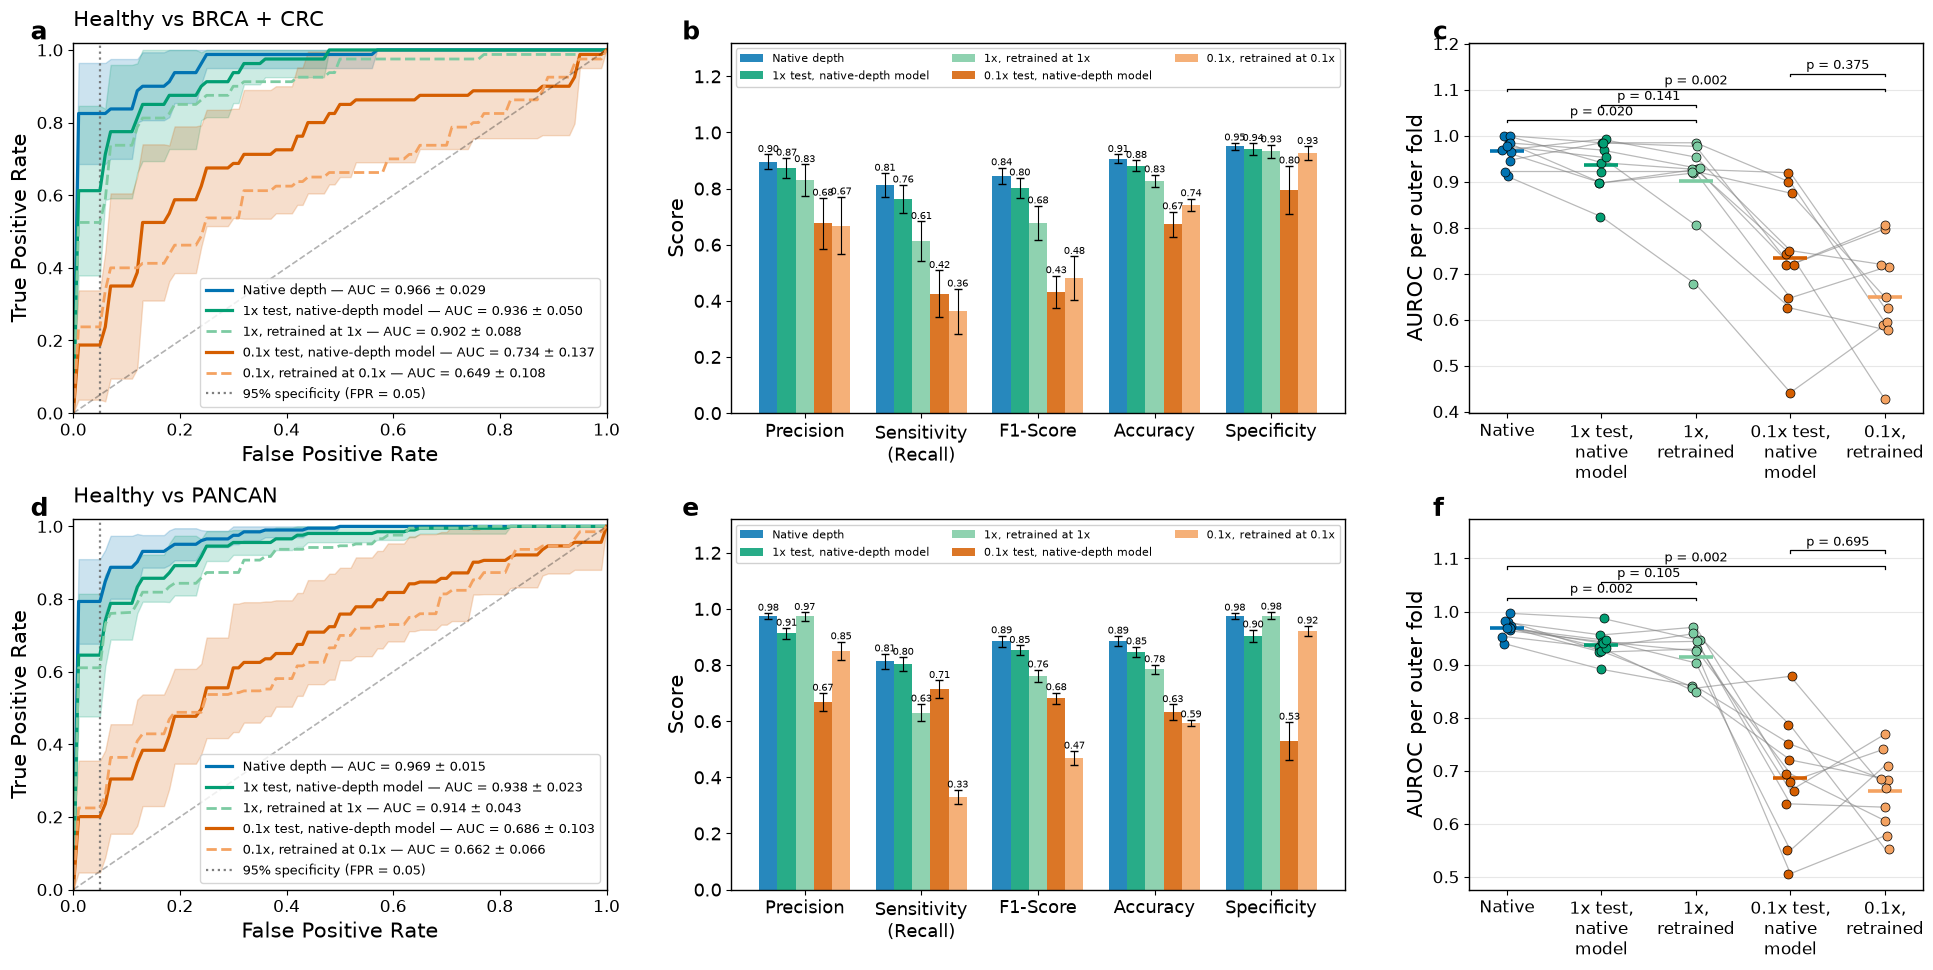

In [5]:
fig, axes = plt.subplots(len(TASKS), 3, figsize=(19.5, 4.9 * len(TASKS)),
                         gridspec_kw={"width_ratios": [1.0, 1.15, 0.85]}, squeeze=False)
letters = iter("abcdef")
test_results = {}
for i, task in enumerate(TASKS):
    panel_roc(axes[i][0], task)
    panel_metrics(axes[i][1], task, error_type="sem")
    test_results[task] = panel_paired_auc(axes[i][2], task)
    axes[i][0].set_title(TASK_LABELS[task], fontsize=15, loc="left", pad=12)
    for ax in axes[i]:
        ax.text(-0.08, 1.06, next(letters), transform=ax.transAxes,
                fontsize=18, fontweight="bold", va="top")
plt.tight_layout()

os.makedirs("output", exist_ok=True)
fig.savefig(out_path("figS8.png"), dpi=300, bbox_inches="tight")
fig.savefig(out_path("figS8.pdf"), bbox_inches="tight")
plt.show()

## Summary numbers

Mean ± sd AUROC over the 10 outer folds, mean sensitivity and achieved specificity at the
95%-specificity threshold, per task and depth, and the paired Wilcoxon tests of the right-hand panels.

In [6]:
for task in TASKS:
    print(TASK_LABELS[task])
    for depth in task_depths(pred, task):
        df = pred[(pred["task"] == task) & (pred["depth"] == depth)]
        aucs = [a for _, _, a in fold_rocs(df)]
        m = collect_fold_metrics(task, depth)
        print(f"  {DEPTH_LABELS[depth]:<20} AUROC {np.mean(aucs):.3f} ± {np.std(aucs):.3f}   "
              f"sensitivity@95%spec {np.mean(m['recall']):.3f}   "
              f"achieved specificity {np.mean(m['specificity']):.3f}")
    print("  paired Wilcoxon (per-fold AUCs):")
    for (a, b), p in test_results[task].items():
        print(f"    {DEPTH_LABELS[a]} vs {DEPTH_LABELS[b]}: p = {p}")
    print()

Healthy vs BRCA + CRC
  Native depth         AUROC 0.966 ± 0.029   sensitivity@95%spec 0.812   achieved specificity 0.951
  1x test, native-depth model AUROC 0.936 ± 0.050   sensitivity@95%spec 0.762   achieved specificity 0.940
  1x, retrained at 1x  AUROC 0.902 ± 0.088   sensitivity@95%spec 0.613   achieved specificity 0.933
  0.1x test, native-depth model AUROC 0.734 ± 0.137   sensitivity@95%spec 0.425   achieved specificity 0.796
  0.1x, retrained at 0.1x AUROC 0.649 ± 0.108   sensitivity@95%spec 0.362   achieved specificity 0.926
  paired Wilcoxon (per-fold AUCs):
    Native depth vs 1x, retrained at 1x: p = 0.01953125
    1x, retrained at 1x vs 1x test, native-depth model: p = 0.140625
    Native depth vs 0.1x, retrained at 0.1x: p = 0.001953125
    0.1x, retrained at 0.1x vs 0.1x test, native-depth model: p = 0.375

Healthy vs PANCAN
  Native depth         AUROC 0.969 ± 0.015   sensitivity@95%spec 0.813   achieved specificity 0.976
  1x test, native-depth model AUROC 0.938 ± 0.0

# QC

Not part of the figure: per-fold winning configurations per (task, depth), and the achieved test
specificity per fold (should scatter around 0.95).

In [7]:
fold_cfg = pd.read_csv(data_path("figS8_fold_configs.csv"))
for task in TASKS:
    print(f"=== {TASK_LABELS[task]}: configuration votes per depth ===")
    sub = fold_cfg[fold_cfg["task"] == task]
    votes = (sub.groupby(["depth", "feature", "selection_type", "top_genes", "classifier"])
             .size().rename("folds").reset_index())
    votes["depth"] = pd.Categorical(votes["depth"], CORE_DEPTHS, ordered=True)
    print(votes.sort_values(["depth", "folds"], ascending=[True, False]).to_string(index=False))
    print()

print("achieved test specificity per fold (must scatter around 0.95):")
for task in TASKS:
    spec_rows = {}
    for depth in task_depths(pred, task):
        df = pred[(pred["task"] == task) & (pred["depth"] == depth)]
        specs = []
        for f, g in df.groupby("fold"):
            thr = g["threshold_95spec"].iloc[0]
            y, yhat = g["y_true"].to_numpy(), (g["score"] >= thr).astype(int).to_numpy()
            tn = np.sum((y == 0) & (yhat == 0)); fp = np.sum((y == 0) & (yhat == 1))
            specs.append(tn / (tn + fp))
        spec_rows[DEPTH_LABELS[depth]] = specs
    folds = sorted(pred[pred["task"] == task]["fold"].unique())
    print(f"\n{TASK_LABELS[task]}:")
    print(pd.DataFrame(spec_rows, index=[f"fold {f}" for f in folds])
          .to_string(float_format=lambda v: f"{v:.3f}"))

=== Healthy vs BRCA + CRC: configuration votes per depth ===
  depth      feature selection_type  top_genes             classifier  folds
   full griffin_diff    fold_change      10000 Support Vector Machine      6
   full griffin_diff      mean_diff      15000 Support Vector Machine      3
   full griffin_diff        p_value      10000 Support Vector Machine      1
  cov1x griffin_diff      mean_diff      15000 Support Vector Machine      8
  cov1x griffin_diff      mean_diff      10000 Support Vector Machine      1
  cov1x griffin_diff       weighted      10000 Support Vector Machine      1
cov0.1x         fslr    fold_change      10000          Random Forest      1
cov0.1x         fslr    fold_change      15000          Random Forest      1
cov0.1x         fslr      mean_diff       2500          Random Forest      1
cov0.1x         fslr      mean_diff      10000 Multi-Layer Perceptron      1
cov0.1x         fslr      mean_diff      15000          Random Forest      1
cov0.1x        


Healthy vs PANCAN:
         Native depth  1x test, native-depth model  1x, retrained at 1x  0.1x test, native-depth model  0.1x, retrained at 0.1x
fold 1          1.000                        0.882                1.000                          0.471                    0.941
fold 2          0.941                        0.882                1.000                          0.882                    0.882
fold 3          1.000                        0.882                0.941                          0.471                    0.882
fold 4          0.941                        0.765                0.882                          0.588                    0.882
fold 5          1.000                        0.938                0.938                          0.750                    1.000
fold 6          1.000                        0.875                1.000                          0.125                    1.000
fold 7          0.938                        0.938                1.000             